# Clasificación de tumores de mama: KNN, SVM y MLP

**Fundamentos de Inteligencia Artificial**, grupo LITIID71, Equipo ClimateAI.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HectorPartido/Tumores-KNN-SVM-MLP/blob/main/Clasificacion_Tumores_KNN_SVM_MLP.ipynb)

Comparamos tres clasificadores supervisados (K vecinos más cercanos, máquina de vectores de soporte y perceptrón multicapa) para decidir si un tumor de mama es **benigno** o **maligno** a partir de 30 características de los núcleos celulares. Los tres se entrenan con los mismos datos de entrenamiento y se evalúan con el mismo conjunto de prueba, con exactitud, precisión, exhaustividad (recall), F1 y matriz de confusión.

**Datos:** Wisconsin Diagnostic Breast Cancer (WDBC), Universidad de Wisconsin, 1995: 569 tumores (357 benignos y 212 malignos) y 30 características numéricas calculadas de imágenes de una punción con aguja fina. Los archivos `wdbc.data` y `wdbc.names` están en la carpeta `data/` del repositorio.

| Sección | Contenido | Responsable |
|---|---|---|
| 1 y 2 | Carga, exploración y preparación de los datos | Hector Martínez Sánchez |
| 3 | K vecinos más cercanos (KNN) | Ismael Alexander Hidalgo Aguilando |
| 4 | Máquina de vectores de soporte (SVM) | Gildardo Emmanuel González García |
| 5 | Perceptrón multicapa (MLP) | Anthony Oziel Ramos López |
| 6 a 8 | Comparación, respuestas a las preguntas y conclusión | Hector Partido Flores |


## 1. Carga y exploración de los datos

**Responsable:** Hector Martínez Sánchez

Cada fila es un tumor. Las columnas son el identificador, el diagnóstico (`M` maligno o `B` benigno) y 30 características: 10 medidas del núcleo celular (radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal), cada una como **media**, **error estándar** y **peor valor** (promedio de los 3 más grandes), según `wdbc.names`.

In [1]:
import time
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEMILLA = 42                      # misma semilla en todo el notebook para que los resultados se repitan
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

In [2]:
# Nombres de las 30 características (orden de wdbc.names): 10 medidas x (media, error estándar, peor valor)
MEDIDAS = ["radio", "textura", "perimetro", "area", "suavidad", "compacidad",
           "concavidad", "puntos_concavos", "simetria", "dimension_fractal"]
CARACTERISTICAS = [f"{m}_{tipo}" for tipo in ("media", "ee", "peor") for m in MEDIDAS]
COLUMNAS = ["id", "diagnostico"] + CARACTERISTICAS

# Se lee data/wdbc.data; en Colab se descarga del repositorio de GitHub
RUTA = Path("data/wdbc.data")
URL = "https://raw.githubusercontent.com/HectorPartido/Tumores-KNN-SVM-MLP/main/data/wdbc.data"
if not RUTA.exists():
    RUTA.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(URL, RUTA)

datos = pd.read_csv(RUTA, header=None, names=COLUMNAS)
print(f"Filas: {datos.shape[0]}, columnas: {datos.shape[1]}")
datos.head()

Filas: 569, columnas: 32


,id,diagnostico,radio_media,textura_media,perimetro_media,area_media,suavidad_media,compacidad_media,concavidad_media,puntos_concavos_media,...,radio_peor,textura_peor,perimetro_peor,area_peor,suavidad_peor,compacidad_peor,concavidad_peor,puntos_concavos_peor,simetria_peor,dimension_fractal_peor
0,842302,M,17.99,10.38,122.80,1001.0,0.118,0.278,0.300,0.147,...,25.38,17.33,184.60,2019.0,0.162,0.666,0.712,0.265,0.460,0.119
1,842517,M,20.57,17.77,132.90,1326.0,0.085,0.079,0.087,0.070,...,24.99,23.41,158.80,1956.0,0.124,0.187,0.242,0.186,0.275,0.089
2,84300903,M,19.69,21.25,130.00,1203.0,0.110,0.160,0.197,0.128,...,23.57,25.53,152.50,1709.0,0.144,0.424,0.450,0.243,0.361,0.088
3,84348301,M,11.42,20.38,77.58,386.1,0.142,0.284,0.241,0.105,...,14.91,26.50,98.87,567.7,0.210,0.866,0.687,0.258,0.664,0.173
4,84358402,M,20.29,14.34,135.10,1297.0,0.100,0.133,0.198,0.104,...,22.54,16.67,152.20,1575.0,0.137,0.205,0.400,0.163,0.236,0.077


In [3]:
print("Valores faltantes:", int(datos.isna().sum().sum()))
print("Identificadores repetidos:", int(datos["id"].duplicated().sum()))
conteo = datos["diagnostico"].map({"B": "Benigno", "M": "Maligno"}).value_counts()
print(pd.DataFrame({"tumores": conteo, "porcentaje": (100 * conteo / len(datos)).round(1)}))
datos[["radio_media", "textura_media", "area_media", "suavidad_media", "area_peor"]].describe().T

Valores faltantes: 0
Identificadores repetidos: 0
             tumores  porcentaje
diagnostico                     
Benigno          357        62.7
Maligno          212        37.3


,count,mean,std,min,25%,50%,75%,max
radio_media,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
textura_media,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
area_media,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
suavidad_media,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
area_peor,569.0,880.583,569.357,185.200,515.300,686.500,1084.000,4254.000


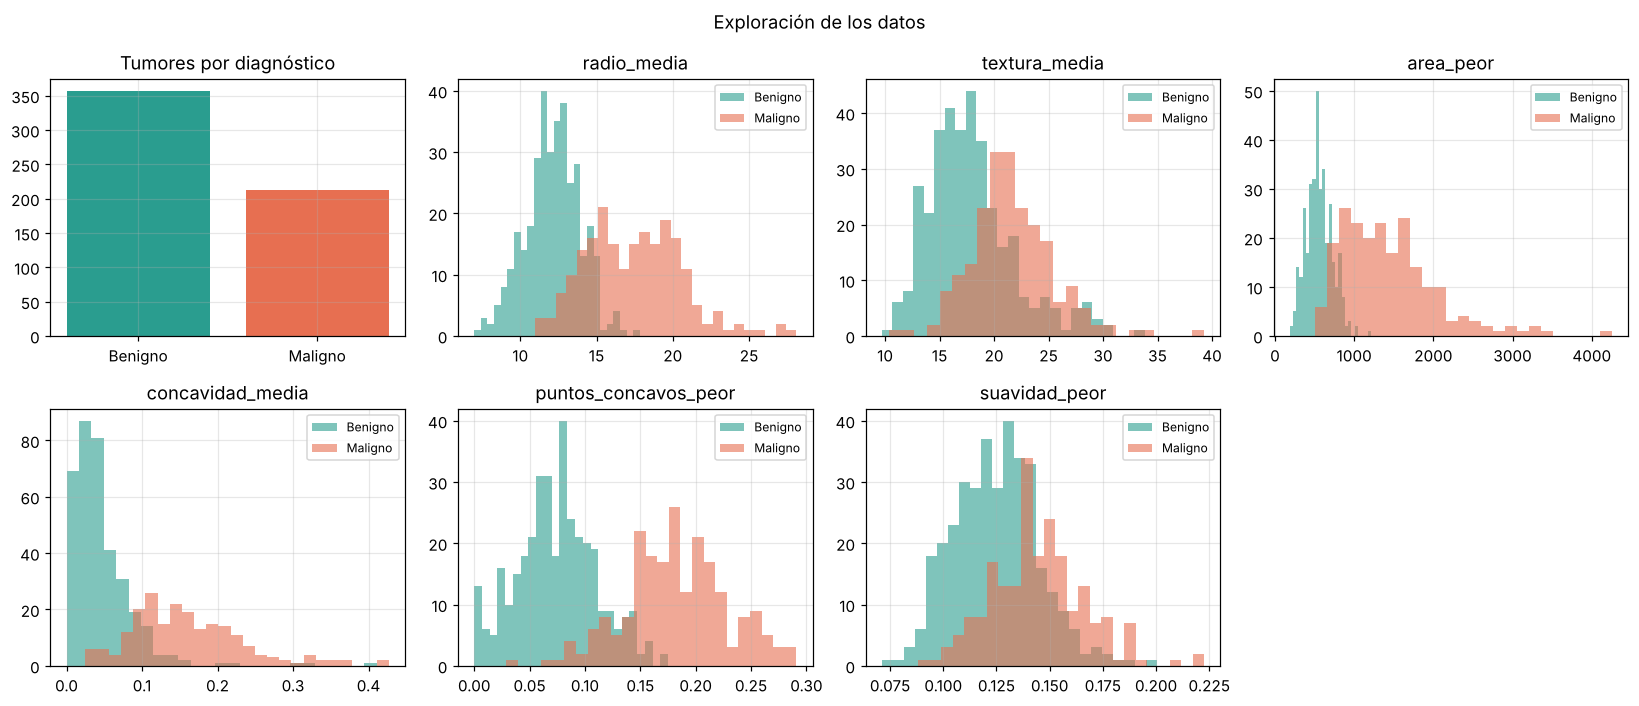

In [4]:
# Distribución de clases y 6 características por diagnóstico
VARIABLES = ["radio_media", "textura_media", "area_peor", "concavidad_media", "puntos_concavos_peor", "suavidad_peor"]
COLORES = {"B": "#2a9d8f", "M": "#e76f51"}
fig, ejes = plt.subplots(2, 4, figsize=(15, 6.5))
ejes = ejes.ravel()
ejes[0].bar(["Benigno", "Maligno"], [conteo["Benigno"], conteo["Maligno"]], color=[COLORES["B"], COLORES["M"]])
ejes[0].set_title("Tumores por diagnóstico")
for eje, var in zip(ejes[1:], VARIABLES):
    for clase, nombre in (("B", "Benigno"), ("M", "Maligno")):
        eje.hist(datos.loc[datos["diagnostico"] == clase, var], bins=25, alpha=0.6, color=COLORES[clase], label=nombre)
    eje.set_title(var)
    eje.legend(fontsize=8)
ejes[-1].axis("off")
fig.suptitle("Exploración de los datos")
fig.tight_layout()
plt.show()

**Resumen del conjunto de datos:**

- **Registros:** 569 tumores.
- **Variables:** 32 columnas. `id` solo identifica al tumor y no se usa para predecir; `diagnostico` es la **variable objetivo**; las otras 30 son las **características de entrada**, todas numéricas.
- **Clases a predecir:** benigno (`B`, 357 tumores) y maligno (`M`, 212 tumores). Es una clasificación binaria.

**Observaciones:**

- No hay valores faltantes ni tumores repetidos.
- Las clases no están equilibradas (63 % benignos y 37 % malignos), así que la partición debe ser **estratificada** para conservar esa proporción en entrenamiento y en prueba.
- Las escalas son muy distintas (el área va de cientos a miles y la suavidad de 0.05 a 0.2). KNN, SVM y MLP usan distancias o gradientes, por eso hay que **estandarizar**.
- Varias características separan bien las clases (el peor valor del área y de los puntos cóncavos casi no se traslapan), lo que anticipa una exactitud alta.

## 2. Preparación de los datos

**Responsable:** Hector Martínez Sánchez

- **Variable objetivo:** maligno = 1 y benigno = 0. La clase positiva es **maligno**: precisión, exhaustividad y F1 se calculan sobre ella.
- **Partición:** 80 % entrenamiento y 20 % prueba, estratificada y con `random_state = 42`. El conjunto de prueba no se toca hasta evaluar.
- **Estandarización:** cada modelo es un `Pipeline` con `StandardScaler`. Así la media y la desviación se calculan solo con entrenamiento (y en cada pliegue de la validación cruzada), sin filtrar información de prueba.
- **Ajuste de hiperparámetros:** `GridSearchCV` con validación cruzada estratificada de 5 pliegues sobre entrenamiento, optimizando **F1**, que equilibra no dejar pasar malignos (exhaustividad) y no alarmar de más (precisión).

In [5]:
X = datos[CARACTERISTICAS]
y = (datos["diagnostico"] == "M").astype(int)          # 1 = maligno, 0 = benigno

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

VALIDACION = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print(f"Entrenamiento: {len(X_train)} tumores ({y_train.mean():.1%} malignos)")
print(f"Prueba:        {len(X_test)} tumores ({y_test.mean():.1%} malignos)")

Entrenamiento: 455 tumores (37.4% malignos)
Prueba:        114 tumores (36.8% malignos)


In [6]:
# Evaluación común para los 3 modelos: todos se miden igual y con el mismo conjunto de prueba
resultados = {}


def evaluar(nombre, busqueda, segundos_ajuste):
    """Mide el mejor modelo de la búsqueda en prueba, guarda sus métricas y dibuja su matriz de confusión."""
    modelo = busqueda.best_estimator_
    inicio = time.perf_counter()
    y_pred = modelo.predict(X_test)
    milisegundos = (time.perf_counter() - inicio) * 1000
    matriz = confusion_matrix(y_test, y_pred)
    # KNN y MLP dan probabilidad de maligno; la SVM da la distancia a la frontera (sirve igual para el AUC)
    puntaje = modelo.predict_proba(X_test)[:, 1] if hasattr(modelo, "predict_proba") else modelo.decision_function(X_test)
    resultados[nombre] = {
        "modelo": modelo,
        "mejores_hiperparametros": busqueda.best_params_,
        "F1 validación cruzada": busqueda.best_score_,
        "Exactitud entrenamiento": accuracy_score(y_train, modelo.predict(X_train)),
        "Exactitud": accuracy_score(y_test, y_pred),
        "Precisión": precision_score(y_test, y_pred),
        "Exhaustividad": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, puntaje),
        "puntaje": puntaje,
        "Malignos no detectados (FN)": int(matriz[1, 0]),
        "Benignos marcados como malignos (FP)": int(matriz[0, 1]),
        "Ajuste (s)": segundos_ajuste,
        "Predicción de prueba (ms)": milisegundos,
    }
    r = resultados[nombre]
    print(f"Mejores hiperparámetros: {busqueda.best_params_}")
    print(f"F1 en validación cruzada: {r['F1 validación cruzada']:.3f}")
    print(f"Exactitud: entrenamiento {r['Exactitud entrenamiento']:.3f}, prueba {r['Exactitud']:.3f}")
    print(f"Precisión {r['Precisión']:.3f} | Exhaustividad {r['Exhaustividad']:.3f} | F1 {r['F1']:.3f}")
    print(f"Tiempo: ajuste {segundos_ajuste:.2f} s, predicción de {len(X_test)} tumores {milisegundos:.1f} ms")
    ConfusionMatrixDisplay(matriz, display_labels=["Benigno", "Maligno"]).plot(cmap="Blues", colorbar=False)
    plt.title(f"Matriz de confusión: {nombre} (prueba)")
    plt.xlabel("Diagnóstico que da el modelo")
    plt.ylabel("Diagnóstico real")
    plt.grid(False)
    plt.show()
    return r

## 3. K vecinos más cercanos (KNN)

**Responsable:** Ismael Alexander Hidalgo Aguilando

KNN no aprende parámetros: guarda los tumores de entrenamiento y clasifica uno nuevo por votación de sus *k* vecinos más parecidos. Se busca:

- `n_neighbors` (k) de 1 a 30: con k pequeño el modelo memoriza (sobreajuste) y con k grande suaviza demasiado (subajuste).
- `weights`: todos los vecinos votan igual (`uniform`) o pesan más los cercanos (`distance`).
- `metric`: distancia euclidiana o Manhattan.

In [7]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([("escala", StandardScaler()), ("modelo", KNeighborsClassifier())])
rejilla_knn = {
    "modelo__n_neighbors": list(range(1, 31)),
    "modelo__weights": ["uniform", "distance"],
    "modelo__metric": ["euclidean", "manhattan"],
}
busqueda_knn = GridSearchCV(knn, rejilla_knn, cv=VALIDACION, scoring="f1", n_jobs=-1, return_train_score=True)
inicio = time.perf_counter()
busqueda_knn.fit(X_train, y_train)
segundos_knn = time.perf_counter() - inicio
print(f"{len(busqueda_knn.cv_results_['params'])} combinaciones x 5 pliegues en {segundos_knn:.1f} s")

120 combinaciones x 5 pliegues en 5.1 s


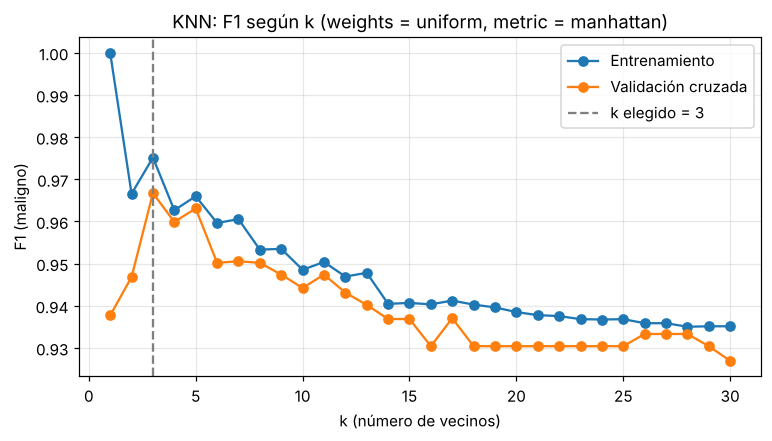

In [8]:
# F1 en entrenamiento y en validación cruzada según k (con los mejores weights y metric)
cv = pd.DataFrame(busqueda_knn.cv_results_)
mejor = busqueda_knn.best_params_
curva = cv[(cv["param_modelo__weights"] == mejor["modelo__weights"])
           & (cv["param_modelo__metric"] == mejor["modelo__metric"])].sort_values("param_modelo__n_neighbors")
plt.figure(figsize=(8, 4))
plt.plot(curva["param_modelo__n_neighbors"], curva["mean_train_score"], "o-", label="Entrenamiento")
plt.plot(curva["param_modelo__n_neighbors"], curva["mean_test_score"], "o-", label="Validación cruzada")
plt.axvline(mejor["modelo__n_neighbors"], color="gray", ls="--", label=f"k elegido = {mejor['modelo__n_neighbors']}")
plt.xlabel("k (número de vecinos)")
plt.ylabel("F1 (maligno)")
plt.title(f"KNN: F1 según k (weights = {mejor['modelo__weights']}, metric = {mejor['modelo__metric']})")
plt.legend()
plt.show()

Mejores hiperparámetros: {'modelo__metric': 'manhattan', 'modelo__n_neighbors': 3, 'modelo__weights': 'uniform'}
F1 en validación cruzada: 0.967
Exactitud: entrenamiento 0.985, prueba 0.965
Precisión 1.000 | Exhaustividad 0.905 | F1 0.950
Tiempo: ajuste 5.14 s, predicción de 114 tumores 11.5 ms


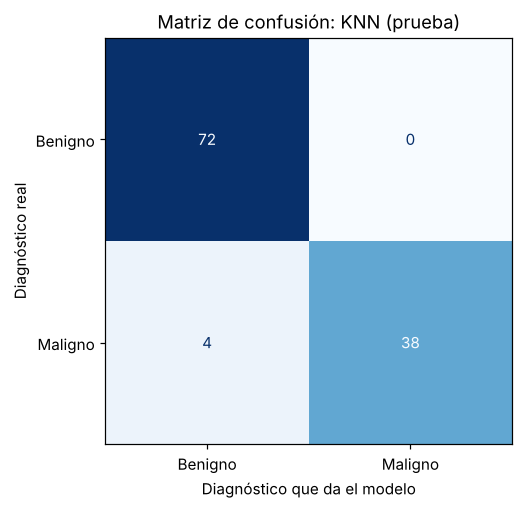

In [9]:
r_knn = evaluar("KNN", busqueda_knn, segundos_knn)

**Interpretación (KNN):**

- El mejor modelo usa k = 3, votación uniforme y distancia Manhattan, con F1 de 0.967 en validación cruzada (con distancia euclidiana el máximo fue 0.963).
- La curva muestra el compromiso de k. Con k = 1 el F1 de entrenamiento es 1.000 pero en validación baja a 0.938: el modelo memoriza (sobreajuste). Con k de 15 a 30 las dos curvas bajan juntas hasta 0.93: el modelo se vuelve demasiado general (subajuste).
- En prueba acierta 110 de 114 tumores (exactitud 0.965). No marca ningún benigno como maligno (precisión 1.000), pero se le escapan 4 de los 42 malignos (exhaustividad 0.905).
- Es el más lento al predecir, porque compara cada tumor nuevo contra los 455 de entrenamiento.

## 4. Máquina de vectores de soporte (SVM)

**Responsable:** Gildardo Emmanuel González García

La SVM busca la frontera que separa las clases con el **margen más amplio**. Solo los tumores cercanos a la frontera (vectores de soporte) la definen. Se prueban dos núcleos:

- **Lineal:** frontera plana. Se ajusta `C`, que controla cuánto se castigan los errores (C grande, margen estrecho y riesgo de sobreajuste).
- **RBF:** frontera curva. Además de `C`, se ajusta `gamma`, que define qué tan lejos llega la influencia de cada tumor.

In [10]:
from sklearn.svm import SVC

svm = Pipeline([("escala", StandardScaler()), ("modelo", SVC(random_state=SEMILLA))])
rejilla_svm = [
    {"modelo__kernel": ["linear"], "modelo__C": [0.01, 0.1, 1, 10, 100]},
    {"modelo__kernel": ["rbf"], "modelo__C": [0.1, 1, 10, 100], "modelo__gamma": ["scale", 0.001, 0.01, 0.1, 1]},
]
busqueda_svm = GridSearchCV(svm, rejilla_svm, cv=VALIDACION, scoring="f1", n_jobs=-1, return_train_score=True)
inicio = time.perf_counter()
busqueda_svm.fit(X_train, y_train)
segundos_svm = time.perf_counter() - inicio
print(f"{len(busqueda_svm.cv_results_['params'])} combinaciones x 5 pliegues en {segundos_svm:.1f} s")

25 combinaciones x 5 pliegues en 1.1 s


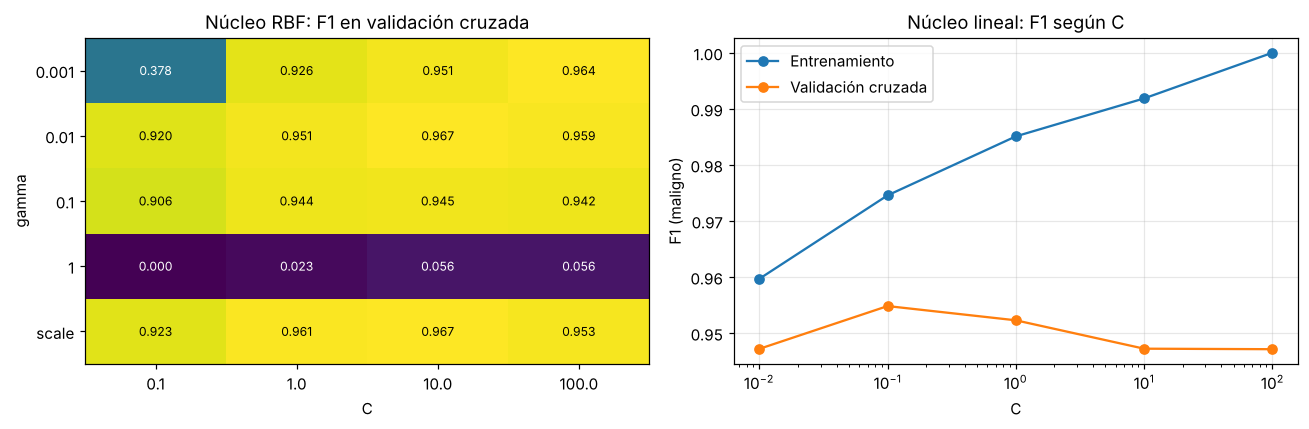

In [11]:
# F1 en validación cruzada de cada combinación (mapa de C y gamma para RBF, línea para el núcleo lineal)
cv = pd.DataFrame(busqueda_svm.cv_results_)
rbf = cv[cv["param_modelo__kernel"] == "rbf"].pivot_table(
    index="param_modelo__gamma", columns="param_modelo__C", values="mean_test_score")
lineal = cv[cv["param_modelo__kernel"] == "linear"].sort_values("param_modelo__C")
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
im = a.imshow(rbf.values, cmap="viridis", aspect="auto")
a.set_xticks(range(rbf.shape[1]), rbf.columns)
a.set_yticks(range(rbf.shape[0]), rbf.index)
for i in range(rbf.shape[0]):
    for j in range(rbf.shape[1]):
        a.text(j, i, f"{rbf.values[i, j]:.3f}", ha="center", va="center", fontsize=8,
               color="black" if rbf.values[i, j] > 0.5 else "white")
a.set_xlabel("C")
a.set_ylabel("gamma")
a.set_title("Núcleo RBF: F1 en validación cruzada")
a.grid(False)
b.semilogx(lineal["param_modelo__C"].astype(float), lineal["mean_train_score"], "o-", label="Entrenamiento")
b.semilogx(lineal["param_modelo__C"].astype(float), lineal["mean_test_score"], "o-", label="Validación cruzada")
b.set_xlabel("C")
b.set_ylabel("F1 (maligno)")
b.set_title("Núcleo lineal: F1 según C")
b.legend()
fig.tight_layout()
plt.show()

Mejores hiperparámetros: {'modelo__C': 10, 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}
F1 en validación cruzada: 0.967
Exactitud: entrenamiento 0.989, prueba 0.974
Precisión 1.000 | Exhaustividad 0.929 | F1 0.963
Tiempo: ajuste 1.12 s, predicción de 114 tumores 2.3 ms


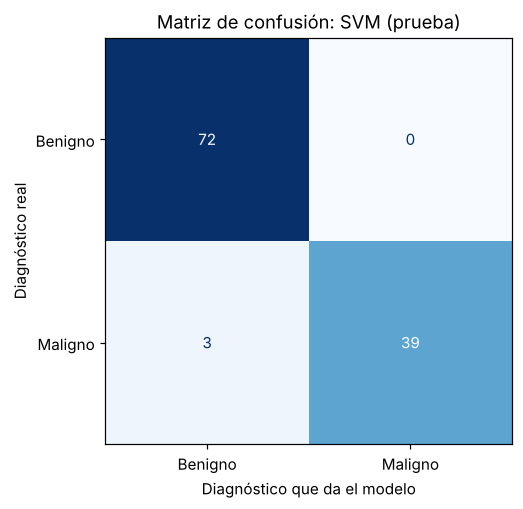

Vectores de soporte: 82 de 455 tumores de entrenamiento


In [12]:
r_svm = evaluar("SVM", busqueda_svm, segundos_svm)
print(f"Vectores de soporte: {busqueda_svm.best_estimator_.named_steps['modelo'].n_support_.sum()} "
      f"de {len(X_train)} tumores de entrenamiento")

**Interpretación (SVM):**

- El mejor modelo usa el núcleo RBF con C = 10 y gamma = "scale" (1/30, unos 0.033 con datos estandarizados), con F1 de 0.967 en validación cruzada. El núcleo lineal llega a 0.955 (C = 0.1): los datos casi se separan con un plano, pero una frontera curva ayuda un poco.
- El mapa muestra el sobreajuste con gamma = 1: cada tumor solo se parece a sí mismo, así que el modelo memoriza el entrenamiento (F1 de 1.000) y a los tumores nuevos los clasifica casi todos como benignos (F1 menor a 0.06). En el núcleo lineal pasa algo parecido con C = 100: 1.000 en entrenamiento y 0.947 en validación.
- En prueba acierta 111 de 114 tumores (exactitud 0.974), con precisión 1.000 y exhaustividad 0.929: se le escapan 3 de los 42 malignos.
- Solo 82 de los 455 tumores de entrenamiento (los vectores de soporte) definen la frontera, y es el más rápido de ajustar.

## 5. Perceptrón multicapa (MLP)

**Responsable:** Anthony Oziel Ramos López

El MLP es una red neuronal: las 30 características entran a una o dos capas ocultas de neuronas con activación ReLU, y la salida da la probabilidad de que el tumor sea maligno. Los pesos se aprenden con el optimizador Adam (hasta 2,000 épocas). Se busca:

- `hidden_layer_sizes`: tamaño de la red (16, 32 o 64 neuronas en una capa, o dos capas de 32 y 16).
- `alpha`: regularización L2. Castiga los pesos grandes: con alpha pequeño la red puede memorizar el entrenamiento (sobreajuste) y con alpha muy grande queda demasiado simple (subajuste).

In [13]:
from sklearn.neural_network import MLPClassifier

mlp = Pipeline([("escala", StandardScaler()),
                ("modelo", MLPClassifier(max_iter=2000, random_state=SEMILLA))])
rejilla_mlp = {
    "modelo__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16)],
    "modelo__alpha": [0.0001, 0.001, 0.01, 0.1, 1.0, 3.0, 10.0],
}
busqueda_mlp = GridSearchCV(mlp, rejilla_mlp, cv=VALIDACION, scoring="f1", n_jobs=-1, return_train_score=True)
inicio = time.perf_counter()
busqueda_mlp.fit(X_train, y_train)
segundos_mlp = time.perf_counter() - inicio
print(f"{len(busqueda_mlp.cv_results_['params'])} combinaciones x 5 pliegues en {segundos_mlp:.1f} s")

28 combinaciones x 5 pliegues en 15.5 s


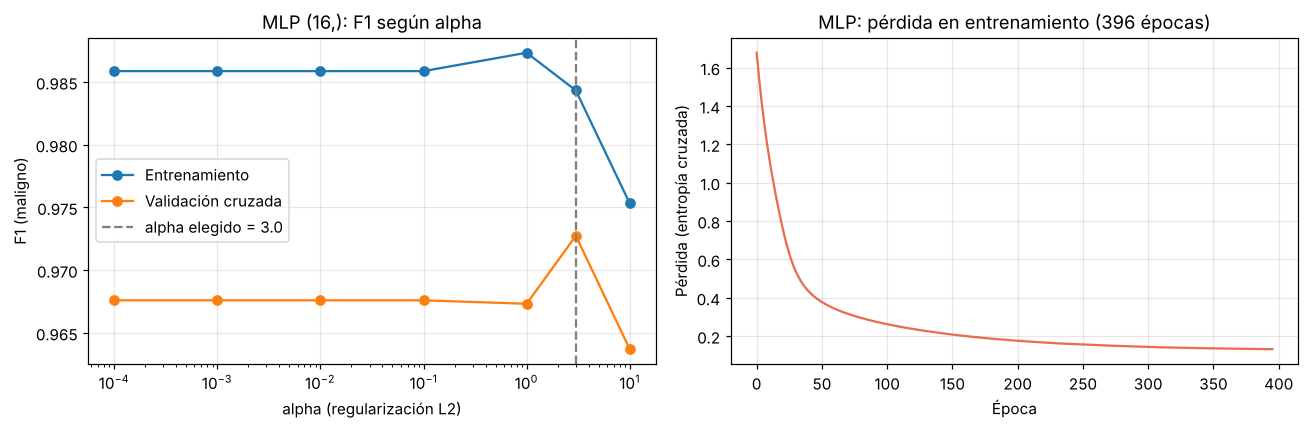

In [14]:
# Efecto de la regularización (alpha) y curva de pérdida del mejor MLP
cv = pd.DataFrame(busqueda_mlp.cv_results_)
mejor = busqueda_mlp.best_params_
capas = mejor["modelo__hidden_layer_sizes"]
curva = cv[cv["param_modelo__hidden_layer_sizes"].apply(lambda c: c == capas)].sort_values("param_modelo__alpha")
red = busqueda_mlp.best_estimator_.named_steps["modelo"]
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
a.semilogx(curva["param_modelo__alpha"].astype(float), curva["mean_train_score"], "o-", label="Entrenamiento")
a.semilogx(curva["param_modelo__alpha"].astype(float), curva["mean_test_score"], "o-", label="Validación cruzada")
a.axvline(mejor["modelo__alpha"], color="gray", ls="--", label=f"alpha elegido = {mejor['modelo__alpha']}")
a.set_xlabel("alpha (regularización L2)")
a.set_ylabel("F1 (maligno)")
a.set_title(f"MLP {capas}: F1 según alpha")
a.legend()
b.plot(red.loss_curve_, color="#e76f51")
b.set_xlabel("Época")
b.set_ylabel("Pérdida (entropía cruzada)")
b.set_title(f"MLP: pérdida en entrenamiento ({red.n_iter_} épocas)")
fig.tight_layout()
plt.show()

Mejores hiperparámetros: {'modelo__alpha': 3.0, 'modelo__hidden_layer_sizes': (16,)}
F1 en validación cruzada: 0.973
Exactitud: entrenamiento 0.982, prueba 0.982
Precisión 1.000 | Exhaustividad 0.952 | F1 0.976
Tiempo: ajuste 15.47 s, predicción de 114 tumores 2.0 ms


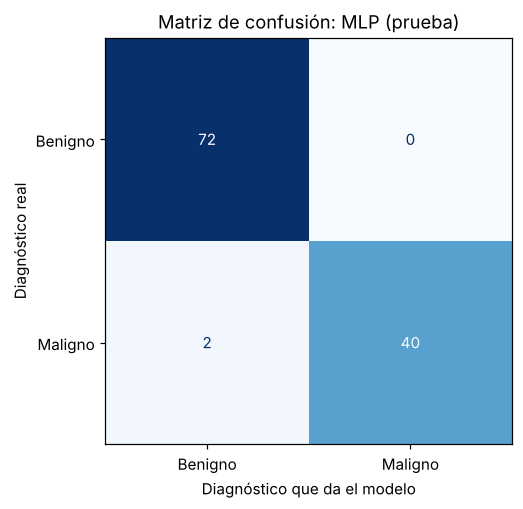

In [15]:
r_mlp = evaluar("MLP", busqueda_mlp, segundos_mlp)

**Interpretación (MLP):**

- La mejor red tiene una capa oculta de 16 neuronas y alpha = 3, con F1 de 0.973 en validación cruzada, el más alto de los tres modelos.
- La gráfica de alpha muestra el efecto de la regularización. Con alpha de 0.0001 a 1 la red llega a 0.986 en entrenamiento y se queda en 0.967 en validación; con alpha = 3 la brecha se cierra (0.984 contra 0.973); con alpha = 10 las dos bajan (0.975 y 0.964): demasiada regularización, subajuste.
- La pérdida baja rápido en las primeras 50 épocas y después se estabiliza. El entrenamiento terminó en 396 épocas, antes del límite de 2,000, así que la red convergió.
- En prueba acierta 112 de 114 tumores (exactitud 0.982), con precisión 1.000 y exhaustividad 0.952: se le escapan 2 de los 42 malignos.
- Una primera versión con `early_stopping` se detenía a las 30 épocas, porque solo reservaba un 10 % del entrenamiento para validar y ese dato era muy ruidoso; quedaba subajustada (F1 de 0.886 en prueba). Por eso se quitó y el sobreajuste se controla con alpha.

## 6. Comparación de los tres modelos

**Responsable:** Hector Partido Flores

Los tres modelos se evaluaron con los mismos 114 tumores de prueba, que ninguno vio al entrenar ni al ajustar hiperparámetros.

In [16]:
tabla = pd.DataFrame(resultados).T.drop(columns=["modelo", "mejores_hiperparametros", "puntaje"])
tabla = tabla.astype(float)
for c in ("Malignos no detectados (FN)", "Benignos marcados como malignos (FP)"):
    tabla[c] = tabla[c].astype(int)
tabla.style.format({c: "{:.3f}" for c in tabla.columns if tabla[c].dtype == float}).highlight_max(
    subset=["Exactitud", "Precisión", "Exhaustividad", "F1", "AUC"], color="#cdeccd")

,F1 validación cruzada,Exactitud entrenamiento,Exactitud,Precisión,Exhaustividad,F1,AUC,Malignos no detectados (FN),Benignos marcados como malignos (FP),Ajuste (s),Predicción de prueba (ms)
KNN,0.967,0.985,0.965,1.000,0.905,0.950,0.974,4,0,5.142,11.523
SVM,0.967,0.989,0.974,1.000,0.929,0.963,0.993,3,0,1.119,2.339
MLP,0.973,0.982,0.982,1.000,0.952,0.976,0.998,2,0,15.469,2.003


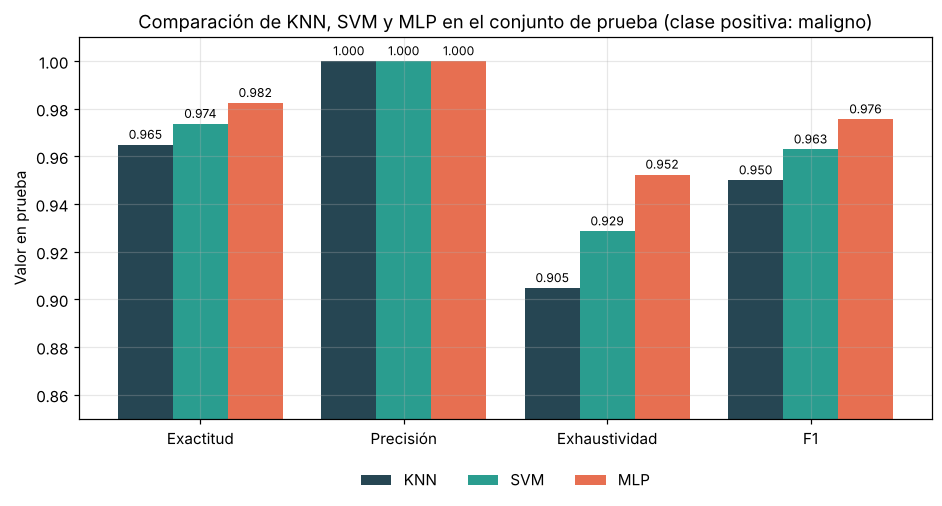

In [17]:
# Métricas de prueba lado a lado
METRICAS = ["Exactitud", "Precisión", "Exhaustividad", "F1"]
COLOR_MODELO = {"KNN": "#264653", "SVM": "#2a9d8f", "MLP": "#e76f51"}
x = np.arange(len(METRICAS))
fig, eje = plt.subplots(figsize=(10, 4.5))
for i, (nombre, r) in enumerate(resultados.items()):
    valores = [r[m] for m in METRICAS]
    barras = eje.bar(x + (i - 1) * 0.27, valores, 0.27, label=nombre, color=COLOR_MODELO[nombre])
    eje.bar_label(barras, fmt="%.3f", fontsize=8, padding=2)
eje.set_xticks(x, METRICAS)
eje.set_ylim(0.85, 1.01)
eje.set_ylabel("Valor en prueba")
eje.set_title("Comparación de KNN, SVM y MLP en el conjunto de prueba (clase positiva: maligno)")
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
plt.show()

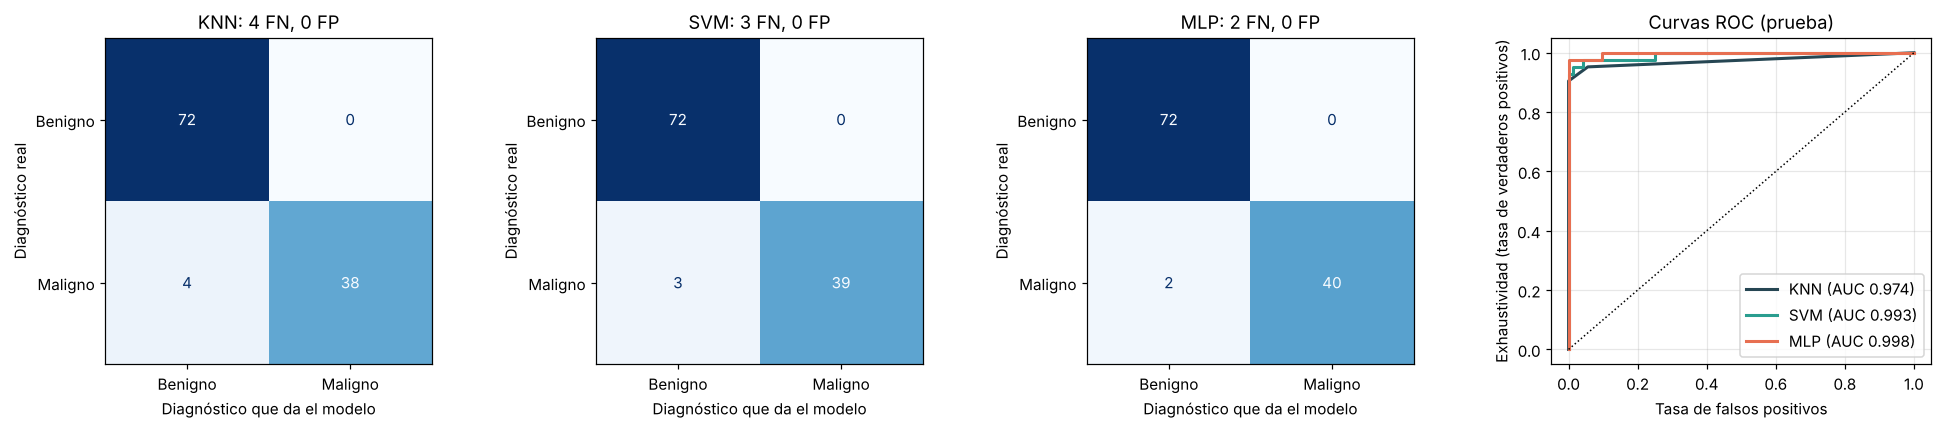

In [18]:
# Matrices de confusión y curvas ROC de los 3 modelos
fig, ejes = plt.subplots(1, 4, figsize=(18, 4))
for eje, (nombre, r) in zip(ejes[:3], resultados.items()):
    ConfusionMatrixDisplay.from_estimator(r["modelo"], X_test, y_test, display_labels=["Benigno", "Maligno"],
                                          cmap="Blues", colorbar=False, ax=eje)
    eje.set_title(f"{nombre}: {r['Malignos no detectados (FN)']} FN, {r['Benignos marcados como malignos (FP)']} FP")
    eje.grid(False)
    eje.set_xlabel("Diagnóstico que da el modelo")
    eje.set_ylabel("Diagnóstico real")
for nombre, r in resultados.items():
    fpr, tpr, _ = roc_curve(y_test, r["puntaje"])
    ejes[3].plot(fpr, tpr, color=COLOR_MODELO[nombre], lw=2, label=f"{nombre} (AUC {r['AUC']:.3f})")
ejes[3].plot([0, 1], [0, 1], "k:", lw=1)
ejes[3].set_xlabel("Tasa de falsos positivos")
ejes[3].set_ylabel("Exhaustividad (tasa de verdaderos positivos)")
ejes[3].legend(loc="lower right")
ejes[3].set_title("Curvas ROC (prueba)")
fig.tight_layout()
plt.show()

### ¿Qué tumores falló cada modelo?

In [19]:
errores = pd.DataFrame({nombre: r["modelo"].predict(X_test) != y_test for nombre, r in resultados.items()})
fallados = errores[errores.any(axis=1)]
detalle = datos.loc[fallados.index, ["id", "diagnostico", "area_peor", "puntos_concavos_peor"]].join(
    fallados.replace({True: "Falla", False: "Acierta"}))
medianas = datos.groupby("diagnostico")[["area_peor", "puntos_concavos_peor"]].median()
print("Mediana por diagnóstico (todos los tumores):")
print(medianas.rename(index={"B": "Benigno", "M": "Maligno"}).round(3))
print()
detalle

Mediana por diagnóstico (todos los tumores):
             area_peor  puntos_concavos_peor
diagnostico                                 
Benigno          547.4                 0.074
Maligno         1303.0                 0.182



,id,diagnostico,area_peor,puntos_concavos_peor,KNN,SVM,MLP
99,862548,M,826.4,0.157,Acierta,Falla,Acierta
39,855138,M,740.4,0.226,Falla,Acierta,Acierta
73,859983,M,812.4,0.138,Falla,Falla,Falla
385,90291,M,758.2,0.136,Falla,Acierta,Acierta
205,879523,M,989.5,0.125,Falla,Falla,Falla


### Exhaustividad contra precisión: el umbral de decisión

Los tres modelos clasifican como maligno cuando la probabilidad es de al menos 0.5. En un diagnóstico, dejar pasar un maligno es peor que revisar de más a un benigno, así que conviene ver qué pasa si el MLP baja ese umbral. **Es solo para ilustrar el compromiso:** un umbral definitivo se elegiría con validación cruzada, no con el conjunto de prueba.

In [20]:
filas = []
for umbral in (0.5, 0.4, 0.3, 0.2, 0.1):
    pred = (resultados["MLP"]["puntaje"] >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    filas.append({"Umbral": umbral, "Malignos no detectados (FN)": fn, "Benignos marcados como malignos (FP)": fp,
                  "Exhaustividad": vp / (vp + fn), "Precisión": vp / (vp + fp)})
pd.DataFrame(filas).set_index("Umbral")

,Malignos no detectados (FN),Benignos marcados como malignos (FP),Exhaustividad,Precisión
Umbral,,,,
0.5,2,0,0.952,1.000
0.4,1,0,0.976,1.000
0.3,1,2,0.976,0.953
0.2,1,5,0.976,0.891
0.1,0,9,1.000,0.824


## 7. Respuestas a las preguntas

**Responsable:** Hector Partido Flores

### 1. ¿Cuál de los tres algoritmos obtuvo el mejor rendimiento?

La **red neuronal (MLP)**. En el conjunto de prueba tuvo la mayor exactitud (0.982), exhaustividad (0.952), F1 (0.976) y AUC (0.998), y empató con los otros dos en precisión (1.000). También fue la mejor en validación cruzada (F1 de 0.973, contra 0.967 de KNN y de la SVM), así que su ventaja no depende solo de los 114 tumores de prueba.

La SVM quedó en segundo lugar (exactitud 0.974) y KNN en tercero (0.965). Las diferencias son pequeñas: en prueba, cada tumor vale 0.9 puntos de exactitud, y el MLP acertó solo 1 tumor más que la SVM y 2 más que KNN.

### 2. ¿Cuál presentó más errores de clasificación?

**KNN**, con 4 errores de 114 (3.5 %); la SVM tuvo 3 y el MLP 2.

En los tres modelos todos los errores son del mismo tipo: **tumores malignos clasificados como benignos** (falsos negativos). Ninguno marcó un benigno como maligno. Además, los errores se repiten: los 2 tumores que falla el MLP también los fallan la SVM y KNN. Son casos frontera: su peor área (812 y 990) y sus puntos cóncavos (0.138 y 0.125) quedan entre la mediana de los benignos (547 y 0.074) y la de los malignos (1,303 y 0.182), como muestra la tabla de errores de la sección 6.

### 3. ¿Qué diferencias observaste en su comportamiento?

- **Cómo aprenden.** KNN no aprende parámetros: guarda los 455 tumores de entrenamiento y compara cada caso nuevo contra todos, por eso es el más lento al predecir. La SVM resume la frontera en 82 vectores de soporte y fue la más rápida de ajustar. El MLP aprende sus pesos durante cientos de épocas (396) y fue el más lento de ajustar.
- **Dependencia de los hiperparámetros.** En los tres, la validación cruzada mostró el límite entre memorizar y generalizar. KNN con k = 1 llega a 1.000 en entrenamiento pero baja a 0.938 en validación. La SVM con gamma = 1 memoriza el entrenamiento y clasifica casi todo lo nuevo como benigno. El MLP necesitó regularización fuerte (alpha = 3) para cerrar la brecha entre entrenamiento y validación, y con alpha = 10 subajusta.
- **Generalización.** La diferencia entre la exactitud de entrenamiento y la de prueba fue pequeña en los tres (KNN 0.985 contra 0.965, SVM 0.989 contra 0.974, MLP 0.982 contra 0.982). El MLP es el que mejor generaliza.
- **Forma de la frontera.** Con núcleo lineal la SVM llegó a 0.955 de F1 en validación y con núcleo RBF a 0.967: los datos casi se separan con un plano, por eso los tres modelos superan el 96 % de exactitud.
- **Confianza en sus decisiones.** El MLP ordena mejor los casos por probabilidad (AUC de 0.998, contra 0.993 de la SVM y 0.974 de KNN). KNN con k = 3 solo puede dar probabilidades de 0, 1/3, 2/3 o 1, por eso su curva ROC es escalonada.
- **Facilidad de uso.** KNN es el más simple de entender y de explicar. El MLP es el más difícil de configurar (una primera versión con `early_stopping` se detenía demasiado pronto) y el menos interpretable.

### 4. ¿Elegirías el algoritmo con mayor exactitud para este problema?

No elegiríamos un modelo solo por su exactitud. Es una **clasificación binaria médica**, con clases desbalanceadas (63 % benignos) y con errores de costo muy distinto: un falso negativo deja a una persona con cáncer sin diagnóstico ni tratamiento, mientras que un falso positivo solo lleva a estudios adicionales. Un modelo que dijera "benigno" a todos tendría 63 % de exactitud sin detectar un solo cáncer. Por eso el criterio principal debe ser la **exhaustividad (recall) de la clase maligno**, cuidando que la precisión no caiga demasiado (F1 y AUC).

En este caso el MLP, que tiene la mayor exactitud, también tiene la mayor exhaustividad (0.952) y el menor número de malignos no detectados (2 de 42). Así que **sí lo elegiríamos, pero por su exhaustividad y no por su exactitud**. Para usarlo en la práctica ajustaríamos su umbral de decisión: con 0.4 en lugar de 0.5 detecta uno de los 2 malignos que se le escapaban sin ningún falso positivo (ese umbral se tendría que fijar con validación cruzada, no con el conjunto de prueba). Y el modelo serviría como apoyo para el especialista, no para reemplazar su diagnóstico.

## 8. Conclusión

Los tres clasificadores distinguen tumores benignos y malignos con más de 96 % de exactitud cuando se estandarizan los datos y se ajustan sus hiperparámetros con validación cruzada. El **perceptrón multicapa con regularización fuerte (alpha = 3)** fue el mejor en todas las métricas y en validación cruzada, seguido muy de cerca por la SVM con núcleo RBF; KNN fue el que más se equivocó. Los tres fallan en los mismos casos frontera y siempre hacia el lado más peligroso (decir benigno a un maligno), así que en este problema el modelo se debe elegir por su exhaustividad y, en uso real, acompañarse de un umbral de decisión más bajo y de la revisión de un especialista.